In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Customer Churn Project Started!")


Customer Churn Project Started!


In [3]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:

import os

print(os.getcwd())
print(os.listdir())


c:\Users\Admin\Downloads\churn_project
['churn.ipynb', 'Telco-Customer-Churn.csv']


In [6]:
import pandas as pd

df = pd.read_csv("Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
print("Dataset shape:", df.shape)
print(df.columns.tolist())

Dataset shape: (7043, 21)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [8]:

# Check dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check summary statistics
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:

# Check blank values in TotalCharges
print("Blank TotalCharges:",
      (df["TotalCharges"].str.strip() == "").sum())

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:",
      df["TotalCharges"].isnull().sum())

# Check data types
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].dtypes)


Blank TotalCharges: 11
Missing TotalCharges: 11
tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object


In [10]:

# Inspect customers with missing TotalCharges
df.loc[
    df["TotalCharges"].isnull(),
    ["customerID", "tenure", "MonthlyCharges",
     "TotalCharges", "Churn"]
]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [11]:

# Fill TotalCharges with 0 for new customers
df.loc[
    (df["tenure"] == 0) & (df["TotalCharges"].isnull()),
    "TotalCharges"
] = 0

# Verify missing values
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Check dataset shape
print("Dataset shape:", df.shape)

# Check data types
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].dtypes)


Missing TotalCharges: 0
Dataset shape: (7043, 21)
tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


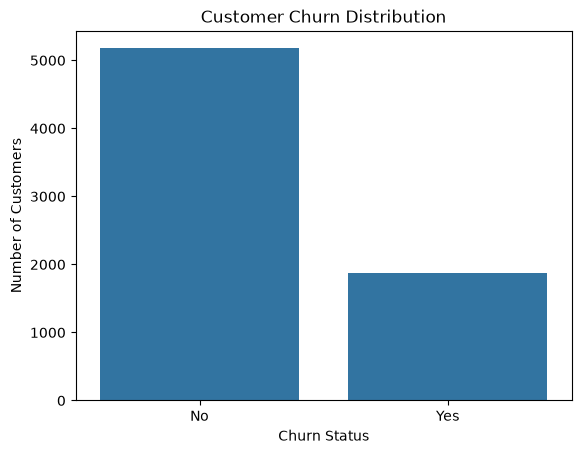

In [12]:

# Count customers who churned and stayed
print(df["Churn"].value_counts())

# Calculate churn percentage
churn_percent = df["Churn"].value_counts(normalize=True) * 100

print("\nChurn Percentage:")
print(churn_percent.round(2))

# Visualize churn distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()


Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


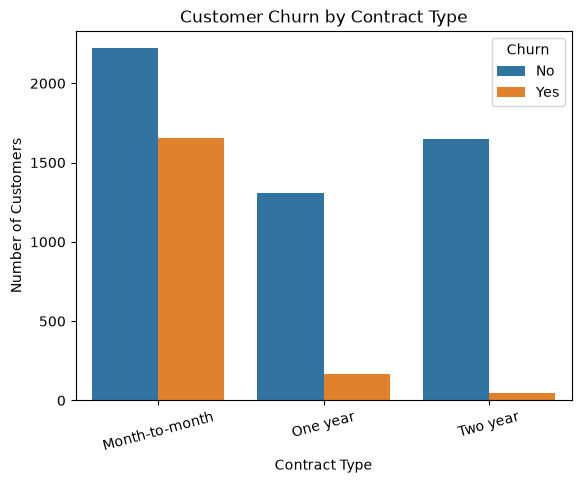

In [15]:

# Churn rate by contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

# Visualize churn by contract
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()


        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


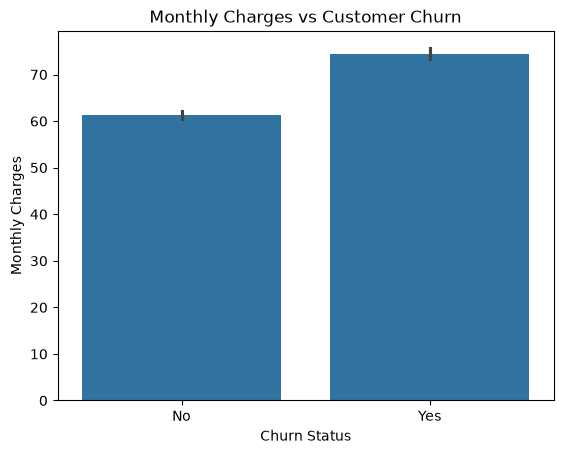

In [17]:

# Compare monthly charges by churn status
print(df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median"]
).round(2))

# Visualize the distribution
sns.barplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.show()


Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


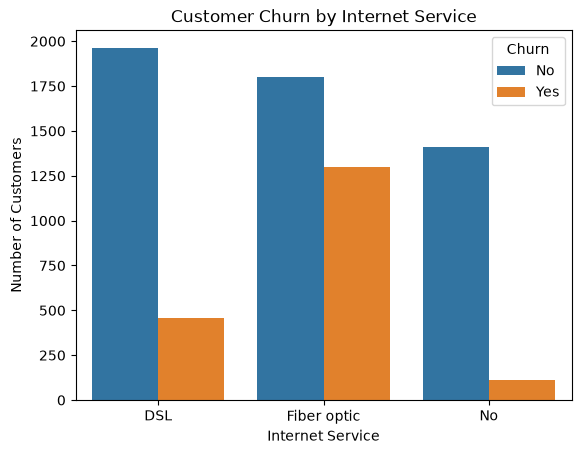

In [18]:

# Churn rate by internet service
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

# Visualize churn by internet service
sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()


Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


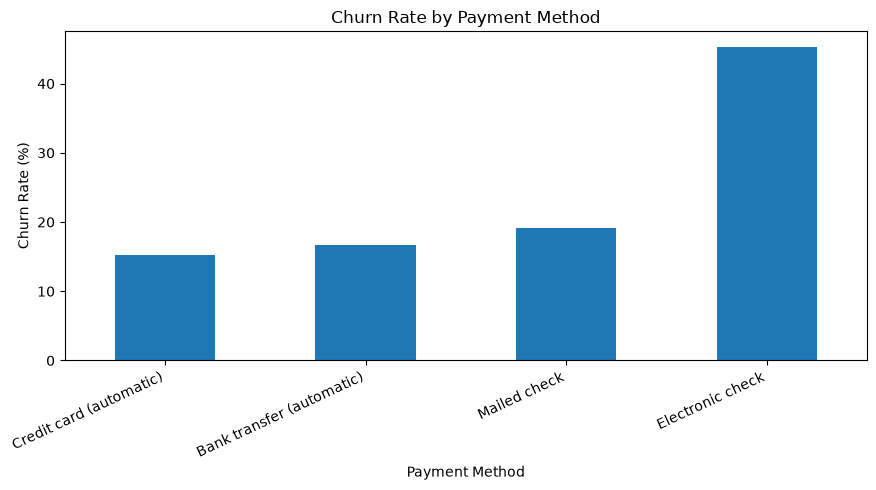

In [19]:

# Churn rate by payment method
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

# Visualize churn rates
payment_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [20]:

# Create a copy for machine learning
ml_df = df.copy()

# Remove customer ID
ml_df = ml_df.drop(columns=["customerID"])

# Check target distribution
print("Dataset shape:", ml_df.shape)
print("\nTarget distribution:")
print(ml_df["Churn"].value_counts())

# Check data types and missing values
print("\nMissing values:", ml_df.isnull().sum().sum())
print("\nData types:")
print(ml_df.dtypes)


Dataset shape: (7043, 20)

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Missing values: 0

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


In [22]:
pip install scikit-learn

^C
Note: you may need to restart the kernel to use updated packages.


In [23]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Separate features and target
X = ml_df.drop(columns=["Churn"])
y = ml_df["Churn"].map({"No": 0, "Yes": 1})

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=["str", "object"]).columns
num_cols = X.select_dtypes(include=["number"]).columns

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Preprocess numerical and categorical features
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# Build pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Model trained successfully!")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Stayed", "Churned"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.4 MB 1.9 MB/s eta 0:00:04
   ----- ---------------------------------- 1.0/8.4 MB 1.8 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.4 MB 2.3 MB/s eta 0:00:03
   ------------ --------------------------- 2.6/8.4 MB 2.6 MB/s eta 0:00:03
   ------------- -------------------------- 2.9/8.4 MB 2.4 MB/s eta 0:00:03
   ------------------ --------------------- 3.9/8.4 MB 2.7 MB/s eta 0:00:02
   ----------------------- ---------------- 5.0/8.4 MB 3.0 MB/s eta 0:00:02
   -------------------------- ------------- 5.5/8.4 MB 3.0 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.4 MB 3.2 MB/s eta 0:00:01
   ------------------------------------- -- 7.9/8.4 MB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 3.5 MB/s  0:00:02
   --------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Model trained successfully!

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[926 109]
 [165 209]]


In [24]:

# Train an improved Logistic Regression model
balanced_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

balanced_model.fit(X_train, y_train)

# Predictions
balanced_pred = balanced_model.predict(X_test)

print("Improved Model Results:\n")
print(classification_report(
    y_test,
    balanced_pred,
    target_names=["Stayed", "Churned"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, balanced_pred))


Improved Model Results:

              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Confusion Matrix:
[[747 288]
 [ 81 293]]


In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Results:\n")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Stayed", "Churned"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Results:

              precision    recall  f1-score   support

      Stayed       0.86      0.82      0.84      1035
     Churned       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409

Confusion Matrix:
[[848 187]
 [137 237]]


In [26]:
# Get feature names after preprocessing
feature_names = (
    balanced_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Logistic Regression coefficients
coefficients = (
    balanced_model.named_steps["classifier"].coef_[0]
)

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print(feature_importance.head(15))

                                      Feature  Coefficient  Importance
1                                 num__tenure    -1.154434    1.154434
38                     cat__Contract_Two year    -0.775518    0.775518
16           cat__InternetService_Fiber optic     0.707981    0.707981
2                         num__MonthlyCharges    -0.676114    0.676114
36               cat__Contract_Month-to-month     0.657713    0.657713
15                   cat__InternetService_DSL    -0.622465    0.622465
3                           num__TotalCharges     0.489698    0.489698
28       cat__TechSupport_No internet service    -0.275403    0.275403
25  cat__DeviceProtection_No internet service    -0.275403    0.275403
17                    cat__InternetService_No    -0.275403    0.275403
19    cat__OnlineSecurity_No internet service    -0.275403    0.275403
34   cat__StreamingMovies_No internet service    -0.275403    0.275403
31       cat__StreamingTV_No internet service    -0.275403    0.275403
22    

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select customer behaviour and billing features
segment_df = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].copy()

# Scale features so different ranges don't dominate
scaler = StandardScaler()
segment_scaled = scaler.fit_transform(segment_df)

print("Segmentation data shape:", segment_scaled.shape)
print("Missing values:", segment_df.isnull().sum().sum())
print("Segmentation data prepared successfully!")

Segmentation data shape: (7043, 3)
Missing values: 0
Segmentation data prepared successfully!


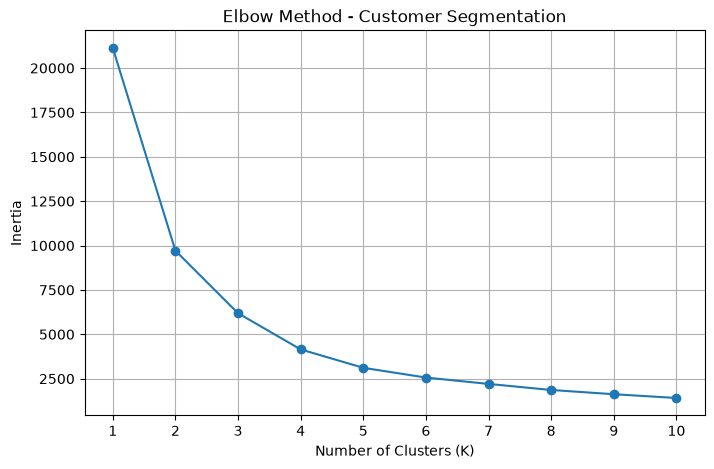

In [28]:
inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(segment_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method - Customer Segmentation")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [29]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["CustomerSegment"] = kmeans.fit_predict(segment_scaled)

print("Customer Segment Counts:")
print(df["CustomerSegment"].value_counts().sort_index())

Customer Segment Counts:
CustomerSegment
0    1703
1    1904
2    2276
3    1160
Name: count, dtype: int64


In [30]:
segment_summary = df.groupby("CustomerSegment").agg(
    Customer_Count=("customerID", "count"),
    Avg_Tenure=("tenure", "mean"),
    Avg_Monthly_Charges=("MonthlyCharges", "mean"),
    Avg_Total_Charges=("TotalCharges", "mean"),
    Churn_Rate=("Churn", lambda x: (x == "Yes").mean() * 100)
).round(2)

print(segment_summary)

                 Customer_Count  Avg_Tenure  Avg_Monthly_Charges  \
CustomerSegment                                                    
0                          1703       10.21                31.78   
1                          1904       59.53                93.31   
2                          2276       15.42                80.78   
3                          1160       53.57                34.91   

                 Avg_Total_Charges  Churn_Rate  
CustomerSegment                                 
0                           302.15       24.66  
1                          5548.65       15.39  
2                          1251.17       48.24  
3                          1835.62        5.00  


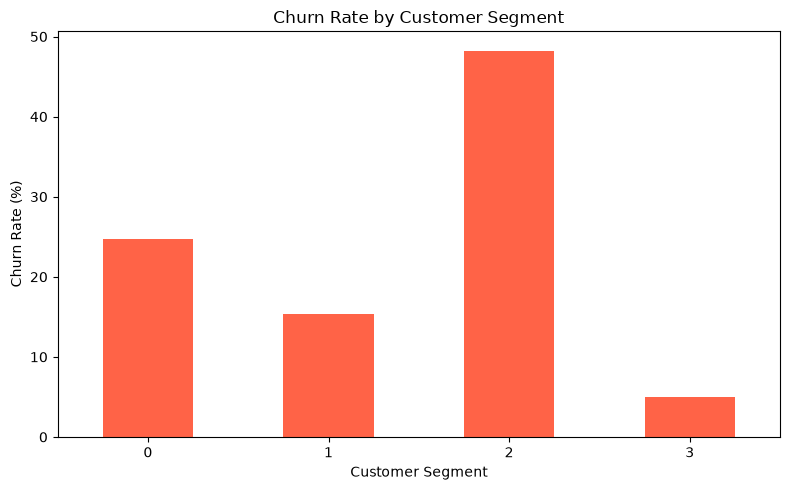

In [31]:
segment_summary["Churn_Rate"].plot(
    kind="bar",
    figsize=(8, 5),
    color="tomato"
)

plt.title("Churn Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [32]:
# Select one customer from the test data
sample_customer = X_test.iloc[[0]]

# Predict churn using our balanced Logistic Regression model
prediction = balanced_model.predict(sample_customer)[0]
probability = balanced_model.predict_proba(sample_customer)[0][1]

print("Predicted Churn:", "Yes" if prediction == 1 else "No")
print(f"Churn Probability: {probability:.2%}")

Predicted Churn: No
Churn Probability: 11.77%


In [33]:
from sklearn.metrics import classification_report, confusion_matrix

# Get churn probabilities
churn_probabilities = balanced_model.predict_proba(X_test)[:, 1]

# Use a 0.40 threshold
threshold = 0.40
threshold_pred = (churn_probabilities >= threshold).astype(int)

print("Threshold:", threshold)
print("\nClassification Report:")
print(classification_report(
    y_test,
    threshold_pred,
    target_names=["Stayed", "Churned"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, threshold_pred))

Threshold: 0.4

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.93      0.64      0.76      1035
     Churned       0.47      0.87      0.61       374

    accuracy                           0.70      1409
   macro avg       0.70      0.75      0.68      1409
weighted avg       0.81      0.70      0.72      1409

Confusion Matrix:
[[664 371]
 [ 50 324]]


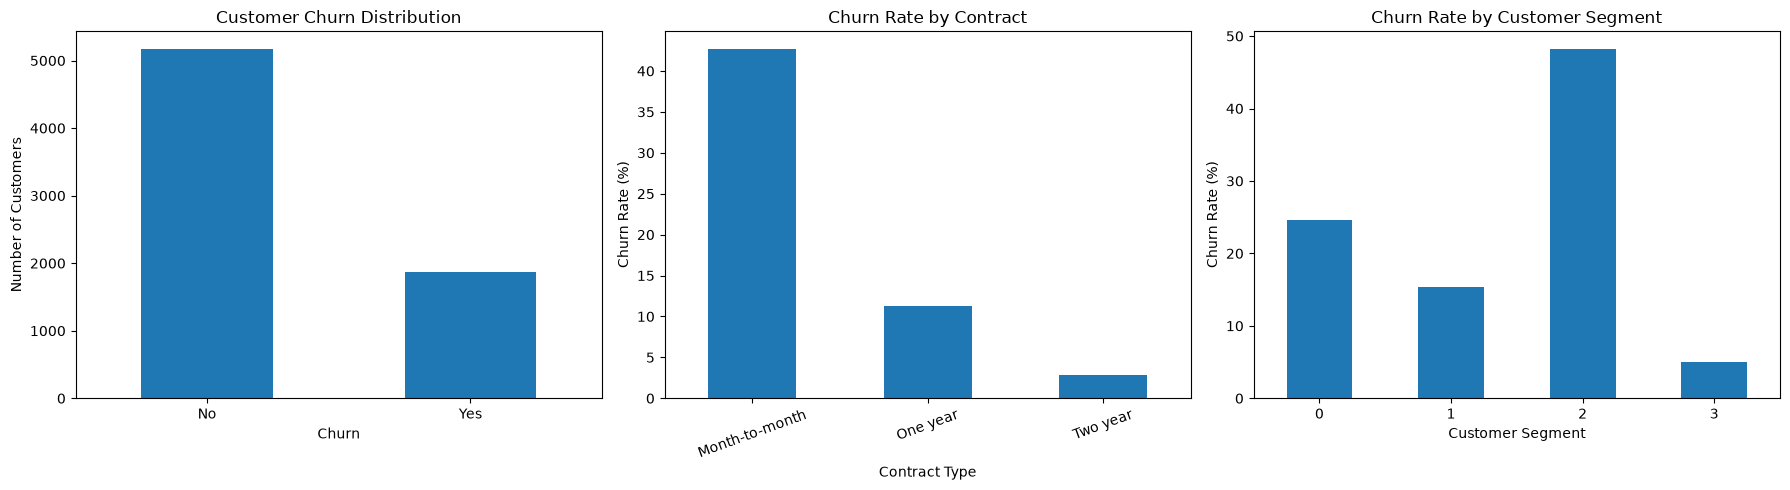

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Churn distribution
df["Churn"].value_counts().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Customer Churn Distribution")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=0)

# 2. Churn by contract
contract_churn = pd.crosstab(
    df["Contract"], df["Churn"], normalize="index"
) * 100

contract_churn["Yes"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Churn Rate by Contract")
axes[1].set_xlabel("Contract Type")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].tick_params(axis="x", rotation=20)

# 3. Churn by customer segment
segment_summary["Churn_Rate"].plot(
    kind="bar", ax=axes[2]
)
axes[2].set_title("Churn Rate by Customer Segment")
axes[2].set_xlabel("Customer Segment")
axes[2].set_ylabel("Churn Rate (%)")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()